# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner


## 0. Setup and Data
We import the tools we need, then store the route data **once** in a list.
Every later section loops over this list, so adding a 4th route is a one-line change.

In [1]:
import inspect
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reusable logic lives in src/ (see README.md for what each module does)
from src.route import Route
from src.forecasters import (Forecaster, MovingAverage, ExponentialSmoothing,
                             LinearTrend, SeasonalNaive)
from src.planning import (find_equilibrium, backtest, tune_alpha,
                          plan_fleet, simulate_weekly_demand)
from src.plotting import plot_actual_vs_forecast
from src.route_planner import RoutePlanner

SEED = 42   # fixed random seed -> same results on every run


def show_source(*objects):
    """Print the source code of classes/functions imported from src/ (handy for learning)."""
    for obj in objects:
        print(inspect.getsource(obj))


# Each route: (name, daily passenger counts for 10 days, fare in UGX)
ROUTE_DATA = [
    ("Kampala-Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2000),
    ("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5000),
    ("Kampala-Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3000),
]

## Task 1: The `Route` Class
A **class** bundles data (passengers, fare) with the actions we can do on that data
(revenue, statistics). 

| Method | What it does 



In [2]:
show_source(Route)   # the class lives in src/route.py

class Route:
    """A taxi route with daily passenger counts and a fixed fare.

    Parameters
    ----------
    name : str
        Route name, e.g. "Kampala-Ntinda".
    passengers : Sequence[float]
        Passengers carried on each day (day 1 first).
    fare : float
        Fare per passenger in UGX.
    """

    def __init__(self, name: str, passengers: Sequence[float], fare: float) -> None:
        self.name = name
        self.passengers = np.array(passengers, dtype=float)  # NumPy array, as required
        self.fare = fare

    def daily_revenue(self) -> np.ndarray:
        """Revenue for each day (UGX) = passengers x fare."""
        return self.passengers * self.fare

    def total_revenue(self) -> float:
        """Total revenue over all days (UGX)."""
        return self.daily_revenue().sum()

    def stats(self) -> Dict[str, float]:
        """Descriptive statistics of daily passenger counts (uses the statistics module)."""
        counts = list(self.passengers)  # stati

Now we build one `Route` object per route and summarise them in a table.

In [3]:
routes = [Route(name, counts, fare) for name, counts, fare in ROUTE_DATA]

summary = pd.DataFrame({
    r.name: {
        "Fare (UGX)": r.fare,
        "Total revenue (UGX)": r.total_revenue(),
        "Mean passengers/day": r.stats()["mean"],
        "Variance": r.stats()["variance"],
        "Std dev": r.stats()["std_dev"],
    }
    for r in routes
}).T

summary.round(2)

,Fare (UGX),Total revenue (UGX),Mean passengers/day,Variance,Std dev
Kampala-Ntinda,2000.0,948000.0,47.4,54.27,7.37
Kampala-Entebbe,5000.0,3390000.0,67.8,45.07,6.71
Kampala-Mukono,3000.0,1560000.0,52.0,26.44,5.14


## Task 2: Supply-Demand Equilibrium (Ntinda route)


In [4]:
show_source(find_equilibrium)   # lives in src/planning.py


# Ntinda: Qd = 120 - 0.02P   and   Qs = 10 + 0.03P
eq_quantity, eq_price = find_equilibrium(120, 0.02, 10, 0.03)
print(f"Equilibrium fare     P* = UGX {eq_price:,.0f}")
print(f"Equilibrium quantity Q* = {eq_quantity:.0f} passengers per trip-hour")

def find_equilibrium(demand_intercept: float, demand_slope: float,
                     supply_intercept: float, supply_slope: float) -> Tuple[float, float]:
    """Solve Qd = a - b*P  and  Qs = c + d*P  for the equilibrium (Q, P).

    Written as a linear system in x = [Q, P]:
        Q + b*P = a
        Q - d*P = c
    """
    A = np.array([[1,  demand_slope],
                  [1, -supply_slope]])
    b = np.array([demand_intercept, supply_intercept])
    Q, P = solve(A, b)
    return Q, P

Equilibrium fare     P* = UGX 2,200
Equilibrium quantity Q* = 76 passengers per trip-hour


**Interpretation:** compare the current fare (UGX 2,000) with the equilibrium fare.

In [5]:
current_fare = routes[0].fare                 # Ntinda's fare: UGX 2,000
demand_now = 120 - 0.02 * current_fare        # how many passengers WANT to travel
supply_now = 10 + 0.03 * current_fare         # how many seats drivers OFFER

print(f"At the current fare of UGX {current_fare:,}:")
print(f"  Demand  = {demand_now:.0f}")
print(f"  Supply  = {supply_now:.0f}")

if current_fare < eq_price:
    print(f"\n-> Fare is BELOW equilibrium (UGX {eq_price:,.0f}).")
    print(f"   Demand exceeds supply by {demand_now - supply_now:.0f} passengers: a shortage (queues).")
elif current_fare > eq_price:
    print(f"\n-> Fare is ABOVE equilibrium (UGX {eq_price:,.0f}): a surplus of seats.")
else:
    print("\n-> Fare is exactly at equilibrium.")

At the current fare of UGX 2,000:
  Demand  = 80
  Supply  = 70

-> Fare is BELOW equilibrium (UGX 2,200).
   Demand exceeds supply by 10 passengers: a shortage (queues).


**Reading the result:**
The current UGX 2,000 fare is **below** the equilibrium fare of **UGX 2,200**.
At UGX 2,000 more people want a ride (80) than drivers supply (70), so there is
a shortage of about 10 passengers per trip-hour. This is why queues form. Raising the
fare towards UGX 2,200 would balance supply and demand (76 passengers per trip-hour).

## Task 3: The `Forecaster` Classes

**Design idea (inheritance):** write one *base class* that defines the "contract":
every forecaster must have a `forecast(history)` method that takes past values and
returns the **next** value. Each subclass fills in *how*.

Because all forecasters share the same method name, we can test them all with the
**same** backtesting code. This is what makes the code reusable: to add a new
forecasting method, write one small subclass.

| Subclass | Idea |
|---|---|
| `MovingAverage(window=3)` | average of the last 3 days |
| `ExponentialSmoothing(alpha)` | weighted average that favours recent days; `alpha` controls how much |
| `LinearTrend` | fit a straight line through history and extend it one day |
| `SeasonalNaive(period=7)` | *(extension)* repeat the value from one week ago |

In [6]:
# These classes live in src/forecasters.py
show_source(Forecaster, MovingAverage, ExponentialSmoothing, LinearTrend, SeasonalNaive)

class Forecaster:
    """Base class. Every forecaster predicts the NEXT value from a history."""

    def __init__(self, name: str = "Forecaster") -> None:
        self.name = name

    def forecast(self, history: np.ndarray) -> float:
        """Return the forecast for the day after `history` (a 1-D array)."""
        raise NotImplementedError("Subclasses must implement forecast().")

    def __repr__(self) -> str:
        return self.name

class MovingAverage(Forecaster):
    """Forecast = mean of the last `window` observations."""

    def __init__(self, window: int = 3) -> None:
        super().__init__(name=f"Moving average ({window}-day)")
        self.window = window

    def forecast(self, history: np.ndarray) -> float:
        return np.mean(history[-self.window:])   # last `window` values

class ExponentialSmoothing(Forecaster):
    """Simple exponential smoothing.

    level_t = alpha * value_t + (1 - alpha) * level_(t-1)
    The forecast is the latest level.
    alpha near 

## Task 4: Rolling-Origin (Walk-Forward) Backtesting

**The idea:** we can't judge a forecaster on data it has already seen. So we pretend
to live through the 10 days again:

1. Stand at the end of day 3 -> forecast day 4 -> compare with what really happened.
2. Move on: stand at the end of day 4 -> forecast day 5 -> compare.
3. ... repeat up to day 10.

At each step the forecaster only sees the **past**. The average size of the errors is the
**MAE** (Mean Absolute Error): lower is better.

$$\text{MAE} = \frac{1}{n}\sum |actual - forecast|$$

In [7]:
show_source(backtest)   # lives in src/planning.py

def backtest(forecaster: Forecaster, data: Sequence[float],
             first_day: int = 4) -> Tuple[np.ndarray, float]:
    """Walk-forward backtest of one forecaster on one series.

    Parameters
    ----------
    forecaster : Forecaster
        Any object with a .forecast(history) method.
    data : array-like
        The full series (day 1 first).
    first_day : int
        First day (1-indexed) to forecast. Default 4 (so 3 days of history).

    Returns
    -------
    forecasts : np.ndarray   forecasts for days first_day ... last day
    mae : float              mean absolute error over those days
    """
    data = np.asarray(data, dtype=float)
    forecasts = []
    for day in range(first_day, len(data) + 1):
        history = data[: day - 1]                 # only days BEFORE `day`
        forecasts.append(forecaster.forecast(history))

    forecasts = np.array(forecasts)
    actual = data[first_day - 1:]                 # what really happened
    mae = np.mean(np.abs(actu

### Tuning alpha by grid search
Exponential smoothing needs an `alpha`. **Grid search** simply means: try every value on a
list (0.1, 0.2, ... 0.9), backtest each, and keep the one with the lowest MAE.
We tune alpha **separately for each route**.

In [8]:
show_source(tune_alpha)   # lives in src/planning.py


for r in routes:
    best_alpha, _ = tune_alpha(r.passengers)
    print(f"{r.name:<17} best alpha = {best_alpha}")

def tune_alpha(data: Sequence[float], alphas: Sequence[float] = np.arange(0.1, 1.0, 0.1),
               first_day: int = 4) -> Tuple[float, Dict[float, float]]:
    """Grid-search the best smoothing alpha. Returns (best_alpha, {alpha: mae})."""
    maes = {}
    for a in alphas:
        _, mae = backtest(ExponentialSmoothing(a), data, first_day)
        maes[round(float(a), 1)] = mae
    best_alpha = min(maes, key=maes.get)          # alpha with smallest MAE
    return best_alpha, maes

Kampala-Ntinda    best alpha = 0.9
Kampala-Entebbe   best alpha = 0.9
Kampala-Mukono    best alpha = 0.9


Now we compare all three models on every route (MAE in passengers and in UGX).

In [9]:
FIRST_DAY = 4   # backtest days 4-10

all_models = {}     # route name -> {model label: forecaster object}
rows = []           # results table

for r in routes:
    best_alpha, _ = tune_alpha(r.passengers, first_day=FIRST_DAY)

    candidates = [
        MovingAverage(window=3),
        ExponentialSmoothing(alpha=best_alpha),
        LinearTrend(),
    ]
    all_models[r.name] = {m.name: m for m in candidates}

    for model in candidates:
        _, mae = backtest(model, r.passengers, FIRST_DAY)
        rows.append({
            "Route": r.name,
            "Model": model.name,
            "MAE (passengers)": mae,
            "MAE (UGX)": mae * r.fare,     # revenue = passengers x fare
        })

results = pd.DataFrame(rows)
results.round(2)

,Route,Model,MAE (passengers),MAE (UGX)
0,Kampala-Ntinda,Moving average (3-day),7.52,15047.62
1,Kampala-Ntinda,Exp. smoothing (alpha=0.9),5.88,11754.55
2,Kampala-Ntinda,Linear trend,7.87,15746.94
3,Kampala-Entebbe,Moving average (3-day),7.19,35952.38
4,Kampala-Entebbe,Exp. smoothing (alpha=0.9),4.73,23651.76
5,Kampala-Entebbe,Linear trend,7.71,38556.69
6,Kampala-Mukono,Moving average (3-day),5.33,16000.00
7,Kampala-Mukono,Exp. smoothing (alpha=0.9),3.79,11380.97
8,Kampala-Mukono,Linear trend,6.39,19171.77


In [10]:
# Best model per route = the one with the smallest MAE
best_rows = results.loc[results.groupby("Route")["MAE (passengers)"].idxmin()]
best_rows[["Route", "Model", "MAE (passengers)", "MAE (UGX)"]].round(2)

,Route,Model,MAE (passengers),MAE (UGX)
4,Kampala-Entebbe,Exp. smoothing (alpha=0.9),4.73,23651.76
7,Kampala-Mukono,Exp. smoothing (alpha=0.9),3.79,11380.97
1,Kampala-Ntinda,Exp. smoothing (alpha=0.9),5.88,11754.55


## Task 5: Day-11 Revenue Forecast and Plot

For each route we:
1. take the best model found above,
2. forecast **day 11 passengers** using all 10 days of history,
3. convert to revenue (passengers x fare).

Because revenue = passengers x a fixed fare, forecasting passengers and then multiplying
gives exactly the same answer as forecasting revenue directly.

In [11]:
day11 = {}   # route name -> dict with everything we need later

for r in routes:
    best_name = best_rows.loc[best_rows["Route"] == r.name, "Model"].iloc[0]
    best_model = all_models[r.name][best_name]

    passengers_11 = best_model.forecast(r.passengers)
    day11[r.name] = {
        "model": best_model,
        "passengers": passengers_11,
        "revenue": passengers_11 * r.fare,
    }

forecast_table = pd.DataFrame({
    name: {
        "Best model": str(info["model"]),
        "Forecast passengers": info["passengers"],
        "Forecast revenue (UGX)": info["revenue"],
    }
    for name, info in day11.items()
}).T

forecast_table

,Best model,Forecast passengers,Forecast revenue (UGX)
Kampala-Ntinda,Exp. smoothing (alpha=0.9),45.247144,90494.28835
Kampala-Entebbe,Exp. smoothing (alpha=0.9),64.227417,321137.08716
Kampala-Mukono,Exp. smoothing (alpha=0.9),50.125324,150375.972204


Plot: actual revenue (days 1-10), the backtest forecasts (days 4-10) and the day-11 forecast.

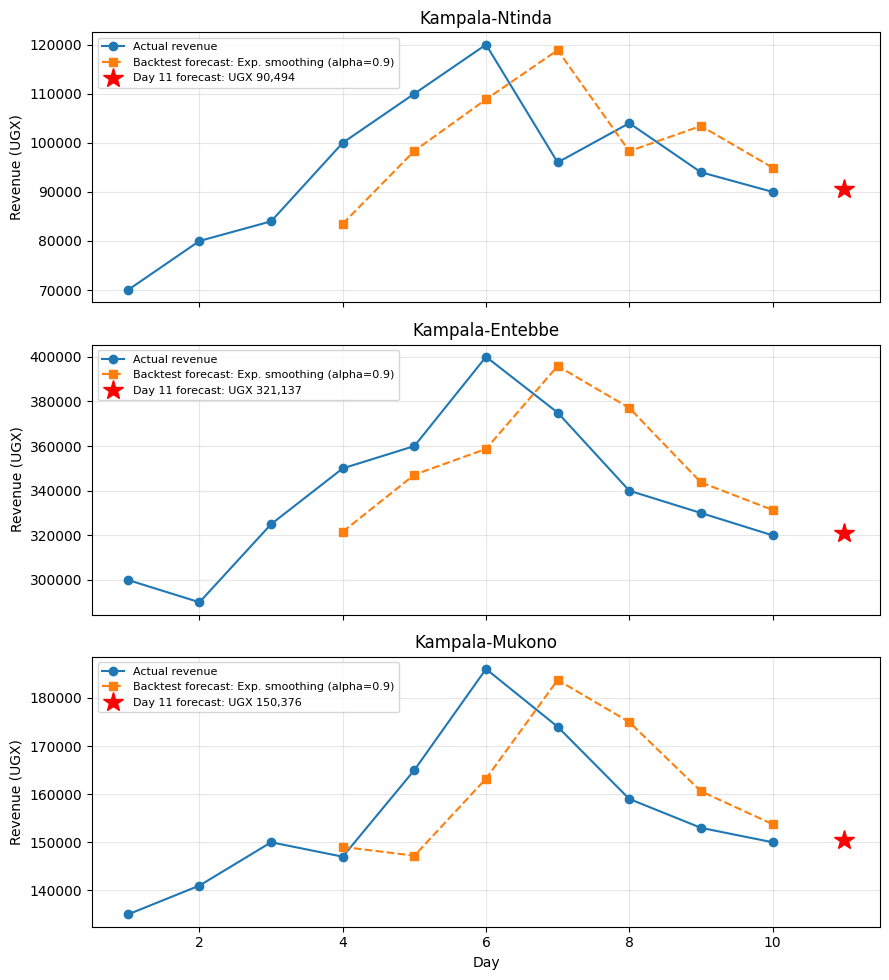

In [12]:
# The plotting helper lives in src/plotting.py
plot_actual_vs_forecast(routes, day11)
plt.show()

## Task 6: Fleet Planning

**Capacity of one vehicle per day:**
8 one-way trips x 14 passengers = **112 passengers per vehicle per day**.

**Vehicles needed on day 11:**

1. `raw = forecast passengers / 112`
2. `with buffer = raw x 1.15` (15% extra for surprises, breakdowns, peaks)
3. **Round up** (`ceil`), because you can't deploy 0.6 of a vehicle, and rounding down
   would leave passengers stranded. We also deploy at least 1 vehicle per route.

In [13]:
show_source(plan_fleet)   # lives in src/planning.py


fleet_rows = []
for r in routes:
    pax = day11[r.name]["passengers"]
    raw, buffered, deploy = plan_fleet(pax)
    fleet_rows.append({
        "Route": r.name,
        "Forecast passengers": pax,
        "Vehicles (raw)": raw,
        "Vehicles (+15% buffer)": buffered,
        "Vehicles to deploy": deploy,
    })

fleet = pd.DataFrame(fleet_rows).set_index("Route")
print(f"Total vehicles for day 11: {fleet['Vehicles to deploy'].sum()}")
fleet.round(2)

def plan_fleet(forecast_passengers: float, trips_per_vehicle: int = 8,
               seats: int = 14, buffer: float = 0.15) -> Tuple[float, float, int]:
    """How many vehicles are needed to carry the forecast passengers?

    Returns (raw_vehicles, vehicles_with_buffer, vehicles_to_deploy).
    """
    capacity = trips_per_vehicle * seats               # passengers per vehicle per day
    raw = forecast_passengers / capacity
    with_buffer = raw * (1 + buffer)
    deploy = max(1, math.ceil(with_buffer))            # round UP, at least 1
    return raw, with_buffer, deploy

Total vehicles for day 11: 3


,Forecast passengers,Vehicles (raw),Vehicles (+15% buffer),Vehicles to deploy
Route,,,,
Kampala-Ntinda,45.25,0.40,0.46,1
Kampala-Entebbe,64.23,0.57,0.66,1
Kampala-Mukono,50.13,0.45,0.51,1


**Reading the result:** each route's forecast demand (roughly 45-65 passengers) is well
below one vehicle's daily capacity of 112, so **one vehicle per route** is enough.
The buffer matters more on busy routes: if demand grew past about 97 passengers a day
(112 / 1.15), a second vehicle would be needed.

 Composition with `RoutePlanner`

In [14]:
show_source(RoutePlanner)   # lives in src/route_planner.py

planners = [RoutePlanner(r, day11[r.name]["model"]) for r in routes]

pd.DataFrame({
    p.route.name: {
        "Forecaster inside": str(p.forecaster),
        "Backtest MAE (passengers)": p.backtest_mae(),
        "Day-11 revenue (UGX)": p.next_day_revenue(),
        "Vehicles to deploy": p.vehicles_needed(),
    }
    for p in planners
}).T

class RoutePlanner:
    """Combine one Route with one Forecaster to answer planning questions.

    This is *composition* ("has-a"): the planner owns a Route object and a
    Forecaster object and delegates work to them, instead of inheriting from them.
    Because it only needs something with a .forecast() method, any Forecaster
    subclass can be plugged in.
    """

    def __init__(self, route: Route, forecaster: Forecaster, first_day: int = 4) -> None:
        self.route = route
        self.forecaster = forecaster
        self.first_day = first_day

    def backtest_forecasts(self) -> np.ndarray:
        """Walk-forward forecasts (passengers) for first_day ... last day."""
        forecasts, _ = backtest(self.forecaster, self.route.passengers, self.first_day)
        return forecasts

    def backtest_mae(self) -> float:
        """Walk-forward mean absolute error, in passengers."""
        _, mae = backtest(self.forecaster, self.route.passengers, self.first_day)
        return 

,Forecaster inside,Backtest MAE (passengers),Day-11 revenue (UGX),Vehicles to deploy
Kampala-Ntinda,Exp. smoothing (alpha=0.9),5.877276,90494.28835,1
Kampala-Entebbe,Exp. smoothing (alpha=0.9),4.730353,321137.08716,1
Kampala-Mukono,Exp. smoothing (alpha=0.9),3.793656,150375.972204,1


## Extension: Weekly Pattern, and Seasonal-Naive vs Moving Average

Real taxi demand has a **weekly rhythm**: busy Fridays, quiet Sundays. A moving average
smooths over this pattern, so it forecasts badly. A **seasonal-naive** forecaster
("same weekday last week") captures it for free.

**Step 1: simulate 60 days** with a weekly pattern plus a little random noise.
We use a fixed random seed so the results are the same every time you run it.

In [15]:
show_source(simulate_weekly_demand)   # lives in src/planning.py


simulated = simulate_weekly_demand(seed=SEED)
print("First 14 days:", simulated[:14].astype(int))

def simulate_weekly_demand(days: int = 60, base: float = 50, noise_sd: float = 2.0,
                           seed: int = 42) -> np.ndarray:
    """Simulate daily passengers with a weekly pattern (day 1 = Monday).

    Weekly multipliers (Mon..Sun): Friday is busiest, Sunday is quietest.
    """
    weekly_factors = np.array([1.00, 1.00, 1.05, 1.10, 1.40, 1.15, 0.60])  # Mon..Sun
    rng = np.random.default_rng(seed)                  # reproducible randomness
    weekday = np.arange(days) % 7                      # 0=Mon ... 6=Sun
    demand = base * weekly_factors[weekday] + rng.normal(0, noise_sd, days)
    return np.round(demand).clip(min=0)                # whole passengers, never negative

First 14 days: [51 48 54 57 66 55 30 49 50 51 57 72 58 32]


**Step 2: backtest both forecasters.** We start at day 15 so both models have at
least two weeks of history to learn from.

In [16]:
contenders = [MovingAverage(window=3), SeasonalNaive(period=7)]

ext_results = {}
for model in contenders:
    fc, mae = backtest(model, simulated, first_day=15)
    ext_results[model.name] = (fc, mae)
    print(f"{model.name:<25} MAE = {mae:.2f} passengers")

ma_mae = ext_results[contenders[0].name][1]
sn_mae = ext_results[contenders[1].name][1]
print(f"\nSeasonal naive beats moving average: {sn_mae < ma_mae}"
      f"  (error cut by {100 * (1 - sn_mae / ma_mae):.0f}%)")

Moving average (3-day)    MAE = 9.42 passengers
Seasonal naive (7-day)    MAE = 1.83 passengers

Seasonal naive beats moving average: True  (error cut by 81%)


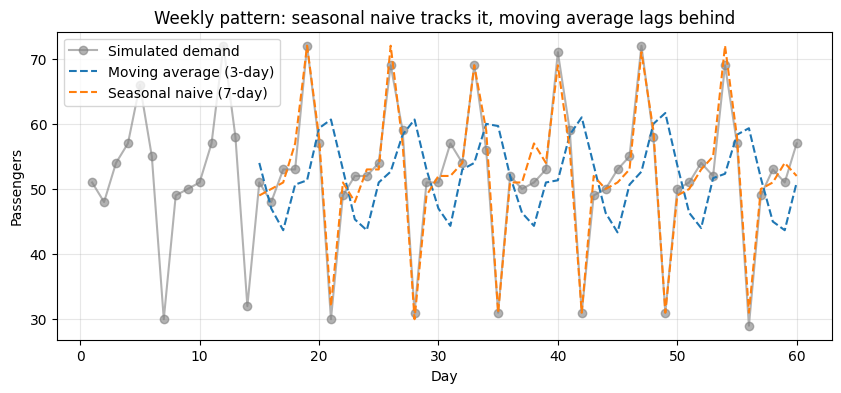

In [17]:
days = np.arange(1, len(simulated) + 1)
plt.figure(figsize=(10, 4))
plt.plot(days, simulated, "o-", color="grey", alpha=0.6, label="Simulated demand")
for model in contenders:
    fc, _ = ext_results[model.name]
    plt.plot(np.arange(15, len(simulated) + 1), fc, "--", label=model.name)
plt.xlabel("Day")
plt.ylabel("Passengers")
plt.title("Weekly pattern: seasonal naive tracks it, moving average lags behind")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Summary

| Task | Result |
|---|---|
| 1 | `Route` class with revenue and statistics |
| 2 | Equilibrium fare **UGX 2,200** (76 passengers); current UGX 2,000 is **below** it, so demand exceeds supply |
| 3 | `Forecaster` base class + `MovingAverage`, `ExponentialSmoothing`, `LinearTrend` |
| 4 | Walk-forward backtest over days 4-10, MAE per model per route, alpha tuned by grid search |
| 5 | Day-11 revenue forecast per route with the best model, plus plot |
| 6 | Fleet plan with 15% buffer, rounded up |
| Extension | Seasonal naive beats the 3-day moving average on simulated weekly data |

### Ideas to extend it
- Add a new route: append one line to `ROUTE_DATA`.
- Add a new forecaster: write a subclass of `Forecaster` with a `forecast()` method.
- Use a different fleet size: call `plan_fleet(pax, trips_per_vehicle=10, seats=14)`.

## Findings & Limitations

**Findings.** The Ntinda fare of UGX 2,000 is below the equilibrium of UGX 2,200: at the current price 80 passengers want a ride but only 70 seats are supplied, which is consistent with queues forming at the stage. A 10% fare rise would clear the market at 76 passengers per trip-hour, provided the stated demand and supply curves are realistic. For forecasting, exponential smoothing with alpha = 0.9 won on every route, which means the most recent days carry the most information; this suits the upward drift in the 10-day data, which a flat 3-day average lags behind. Day-11 revenue is forecast at roughly UGX 90,000 (Ntinda), 321,000 (Entebbe) and 150,000 (Mukono). One vehicle per route is enough, because a vehicle's daily capacity (112 passengers) is far above forecast demand (45 to 65). In the simulated extension, seasonal naive cut the error by about 81% compared with the moving average, so the best model depends on the structure of the data.

**Limitations.** Only 7 forecast points were backtested, too few to separate models with confidence, and the best alpha sits at the edge of the grid, so a wider search might do better. The equilibrium analysis implies fares affect demand, yet the forecasts assume a fixed fare. Capacity ignores peak-hour crowding, so "one vehicle" may be too optimistic at rush hour. Forecasts are single numbers with no uncertainty range, and the weekly-pattern data is synthetic, so the extension shows a method working, not a real-world result. Real UBOS or association data should replace the illustrative counts before any real decision.